In [1]:
!pip -q install -U transformers peft accelerate sacrebleu sentencepiece pandas gradio
# Colab có sẵn torchao quá cũ so với peft mới (gây ImportError khi gắn LoRA); mô hình này không dùng torchao
!pip -q uninstall -y torchao
import os, sys, json, re, io, math, copy, time, random, gc, itertools, types
from dataclasses import dataclass
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from IPython.display import display
assert torch.cuda.is_available(), "Chưa bật GPU: Runtime > Change runtime type > GPU."
DEV = "cuda"
print(torch.__version__, torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB")
CKPT_DIR = "/content/ckpt"            # lưu cache dữ liệu đã dịch; đổi sang thư mục Google Drive nếu muốn giữ khi runtime bị ngắt
os.makedirs(CKPT_DIR, exist_ok=True)
# from google.colab import drive; drive.mount("/content/drive"); CKPT_DIR = "/content/drive/MyDrive/timt_ckpt"; os.makedirs(CKPT_DIR, exist_ok=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


2.14.1+cu130 Tesla T4 14.6 GB


In [2]:
PRESET = "quick"   # "quick" (thử nhanh) -> "default" -> "full"
class CFG:
    seed = 1234
    mask_ratio = 0.20            # bài: che khoảng 20% chữ (vPO)
    n_eval_doc, n_eval_scene = 24, 18
    # kích thước dữ liệu theo PRESET (bài: pre-train 1,2 triệu mẫu, fine-tune 350 nghìn, mcDPO 10 nghìn cặp)
    n_ocr = n_mt = n_ft = n_dpo = 0
PRESETS = {  # n_ocr: ảnh OCR | n_mt: cặp dịch văn bản | n_ft: mẫu TiMT | n_dpo: cặp mcDPO
    "quick":   dict(n_ocr=24,  n_mt=24,  n_ft=48,  n_dpo=24),
    "default": dict(n_ocr=120, n_mt=120, n_ft=300, n_dpo=150),
    "full":    dict(n_ocr=250, n_mt=250, n_ft=600, n_dpo=300),
}
for k, v in PRESETS[PRESET].items(): setattr(CFG, k, v)
print("PRESET =", PRESET, PRESETS[PRESET])


PRESET = quick {'n_ocr': 24, 'n_mt': 24, 'n_ft': 48, 'n_dpo': 24}


In [3]:
# ---- Dữ liệu Anh -> Trung từ sách thuộc về công cộng (thay cho 167 cặp Anh–Việt) ----
# Nhãn tiếng Trung = dịch máy (nhãn GIẢ, giống ý tưởng Trans-en-zh của bài: dịch bằng mô hình rồi lọc).
import re, json, os, random, time, urllib.request

BOOK_URL = "https://www.gutenberg.org/cache/epub/11/pg11.txt"      # Alice's Adventures in Wonderland (đã tải được trên Colab)
MT_NAME  = "Helsinki-NLP/opus-mt-en-zh"
DATA_CACHE = f"{CKPT_DIR}/book_en_zh.json"                          # lưu để không phải dịch lại khi runtime bị ngắt
CJK = "\u4e00-\u9fff"
CJK_ALL = CJK + "\u3000-\u303f\uff00-\uffef"                          # chữ Hán + dấu câu CJK / toàn chiều rộng

def clean_zh(zh):
    zh = re.sub(rf"(?<=[{CJK_ALL}]) +(?=[{CJK_ALL}])", "", zh)     # mô hình dịch hay chèn khoảng trắng giữa chữ Hán và dấu câu
    return zh.strip()

def keep_pair(en, zh, strict=True):
    s = re.sub(r"\s+", "", zh)
    if not s: return False
    cjk = sum("\u4e00" <= c <= "\u9fff" for c in s)
    ok = cjk / len(s) >= 0.6 and not re.search(r"(.{1,20}?)\1{4,}", s)   # đủ chữ Hán, không tự lặp
    if strict: ok = ok and 0.8 <= cjk / max(1, len(en.split())) <= 5.0   # tỉ lệ độ dài hợp lý (heuristic của thầy)
    return ok

def clean_book(raw):
    """Trả về (danh sách đoạn văn thân truyện, danh sách tiêu đề chương)."""
    raw = raw.replace("\r", "")
    m = re.search(r"\*\*\* ?START OF .*?\*\*\*", raw); raw = raw[m.end():] if m else raw
    m = re.search(r"\*\*\* ?END OF ", raw);            raw = raw[:m.start()] if m else raw
    titles = []
    for t in re.findall(r"CHAPTER [IVXLC]+\.\s+([^\n]+)", raw):
        t = t.strip()
        if t and t not in titles: titles.append(t)
    raw = re.sub(r"(?m)^[ \t]*CHAPTER [IVXLC]+\.[^\n]*$", "", raw)                   # bỏ dòng tiêu đề chương (tiêu đề đã lưu ở trên)
    a = raw.find("Alice was beginning to get very tired")          # bỏ mục lục/minh họa ở đầu (mục lục từng lọt vào dữ liệu)
    if a > 0: raw = raw[a:]
    paras = []
    for p in re.split(r"\n\s*\n", raw):
        p = re.sub(r"\[[^\]]*\]", "", p.replace("_", ""))
        p = re.sub(r"\s+", " ", p).strip()
        letters = [c for c in p if c.isalpha()]
        if len(p.split()) < 8 or not letters: continue
        if sum(c.isupper() for c in letters) / len(letters) > 0.3 or p.startswith("CHAPTER"): continue   # tiêu đề / chữ in hoa
        paras.append(p)
    return paras, titles

def build_pairs(raw, translate, max_sents=None):
    paras, titles = clean_book(raw)
    sents = []
    for p in paras:
        for s in re.split(r"(?<=[.!?])\s+", p):
            if 4 <= len(s.split()) <= 45: sents.append(s)
    if max_sents: sents = sents[:max_sents]
    zh = [clean_zh(z) for z in translate(sents)]
    pairs = [[e, z] for e, z in zip(sents, zh) if keep_pair(e, z)]
    tz = [clean_zh(z) for z in translate(titles)]
    short = [[e, z] for e, z in zip(titles, tz) if keep_pair(e, z, strict=False)]
    return {"sent": pairs, "short": short}, dict(paragraphs=len(paras), sentences=len(sents), kept=len(pairs), titles=len(short))

def marian_translate_fn():
    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    tok = AutoTokenizer.from_pretrained(MT_NAME)
    mt = AutoModelForSeq2SeqLM.from_pretrained(MT_NAME).to(DEV).eval()
    tag = ">>cmn_Hans<< " if tok.convert_tokens_to_ids(">>cmn_Hans<<") != tok.unk_token_id else ""
    def translate(texts, bs=32):
        out = []
        for i in range(0, len(texts), bs):
            b = tok([tag + t for t in texts[i:i+bs]], return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEV)
            with torch.no_grad(): g = mt.generate(**b, max_new_tokens=200, num_beams=4)
            out += tok.batch_decode(g, skip_special_tokens=True)
        return out
    return translate, mt

def fetch_book_nltk(path="book.txt"):
    """Bản Alice trong kho ngữ liệu NLTK (lấy từ Project Gutenberg, thuộc về công cộng); không cần truy cập Gutenberg."""
    import nltk
    nltk.download("gutenberg", quiet=True)
    open(path, "w", encoding="utf-8").write(nltk.corpus.gutenberg.raw("carroll-alice.txt"))
    return path

GH_ZIP = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/corpora/gutenberg.zip"   # link cần kiểm tra

def text_from_gutenberg_zip(blob):
    """Lấy carroll-alice.txt từ gói gutenberg.zip của kho nltk_data (GitHub)."""
    import zipfile, io
    z = zipfile.ZipFile(io.BytesIO(blob))
    name = [n for n in z.namelist() if n.endswith("carroll-alice.txt")][0]
    return z.read(name).decode("utf-8", errors="ignore")

def fetch_book_github(path="book.txt"):
    hdr = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) student-NLP-project"}
    blob = urllib.request.urlopen(urllib.request.Request(GH_ZIP, headers=hdr), timeout=120).read()
    open(path, "w", encoding="utf-8").write(text_from_gutenberg_zip(blob))
    return path

def fetch_book(path="book.txt"):
    """Thứ tự: file có sẵn -> NLTK -> Project Gutenberg (có thử lại). Gutenberg có lúc bảo trì (503)."""
    if os.path.exists(path) and os.path.getsize(path) > 50_000:
        print("dùng file có sẵn:", path); return path               # đã tải tay và kéo vào thanh Tệp của Colab
    try:
        fetch_book_nltk(path)
        if os.path.getsize(path) > 50_000:
            print("đã lấy sách từ kho NLTK"); return path
    except Exception as e:
        print("NLTK lỗi:", e)
    try:
        fetch_book_github(path)                                    # tải thẳng gói dữ liệu trên GitHub của nltk_data
        if os.path.getsize(path) > 50_000:
            print("đã lấy sách từ GitHub (nltk_data)"); return path
    except Exception as e:
        print("GitHub lỗi:", e)
    urls = [BOOK_URL, "https://www.gutenberg.org/files/11/11-0.txt", "https://gutenberg.org/cache/epub/11/pg11.txt"]   # link phụ cần kiểm tra
    hdr = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) student-NLP-project"}
    for u in urls:
        for k in range(2):
            try:
                data = urllib.request.urlopen(urllib.request.Request(u, headers=hdr), timeout=60).read()
                if len(data) > 50_000:
                    open(path, "wb").write(data); print("đã tải:", u); return path
            except Exception as e:
                print(f"tải lỗi ({u}, lần {k+1}): {e}"); time.sleep(5 * (k + 1))
    raise RuntimeError("Không lấy được sách. Tải tay một bản văn bản của 'Alice's Adventures in Wonderland' (miền công cộng) "
                       "từ nguồn khác, kéo vào thanh Tệp của Colab với tên book.txt rồi chạy lại ô này.")

# ---- chạy ----
if os.path.exists(DATA_CACHE):
    DATA = json.load(open(DATA_CACHE, encoding="utf-8")); print("đã nạp dữ liệu đã dịch từ", DATA_CACHE)
else:
    raw = open(fetch_book(), encoding="utf-8", errors="ignore").read()
    translate, _mt = marian_translate_fn()
    DATA, st = build_pairs(raw, translate); print("thống kê:", st)
    del _mt; gc.collect(); torch.cuda.empty_cache()
    json.dump(DATA, open(DATA_CACHE, "w", encoding="utf-8"), ensure_ascii=False)
print(f"{len(DATA['sent'])} cặp câu Anh–Trung | {len(DATA['short'])} tiêu đề chương")
for k in (0, len(DATA["sent"]) // 2, len(DATA["sent"]) - 1):
    print("EN:", DATA["sent"][k][0][:100]); print("ZH:", DATA["sent"][k][1][:60]); print()
print("tiêu đề:", DATA["short"][:4])


đã lấy sách từ kho NLTK


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/806k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/805k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.62M [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=200) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

thống kê: {'paragraphs': 703, 'sentences': 1065, 'kept': 995, 'titles': 11}
995 cặp câu Anh–Trung | 11 tiêu đề chương
EN: There was nothing so VERY remarkable in that; nor did Alice think it so VERY much out of the way to 
ZH: 没有什么特别的, 爱丽丝认为它是如此之大听兔子对自己说,"哦,亲爱的!

EN: Half-past one, time for dinner!'
ZH: 半个月后,该吃晚饭了!"

EN: But her sister sat still just as she left her, leaning her head on her hand, watching the setting su
ZH: 但是她妹妹仍然坐在她离开的时候, 把她的头靠在她的手上, 看着落日的太阳, 想到小爱丽丝和她所有的美好冒险, 直到她也开

tiêu đề: [['Down the Rabbit-Hole', '从兔子洞下来'], ['The Pool of Tears', '泪水之池'], ['A Caucus-Race and a Long Tale', '一个核心小组和长篇小说'], ['The Rabbit Sends in a Little Bill', '兔子送来一个小比尔']]


In [4]:
EN_CANDS = ["/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf","/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf",
            "/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf","/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSerif-Regular.ttf","/usr/share/fonts/truetype/liberation/LiberationMono-Regular.ttf"]
EN_BOLD  = ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf","/usr/share/fonts/truetype/dejavu/DejaVuSerif-Bold.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf","/usr/share/fonts/truetype/liberation/LiberationSerif-Bold.ttf"]
EN_FONTS = [p for p in EN_CANDS if os.path.exists(p)]
EN_BOLDF = [p for p in EN_BOLD if os.path.exists(p)] or EN_FONTS
assert EN_FONTS, "Thiếu phông chữ - chạy lại lệnh apt-get ở Cell 1"
_FC = {}
def load_font(path,size):
    if (path,size) not in _FC: _FC[(path,size)]=ImageFont.truetype(path,size)
    return _FC[(path,size)]

def luminance(c): return 0.299*c[0]+0.587*c[1]+0.114*c[2]
def contrast_color(bg,rng):
    return tuple(rng.randint(0,50) for _ in range(3)) if luminance(bg)>140 else tuple(rng.randint(205,255) for _ in range(3))

def make_bg(W,H,rng,kind):
    if kind=="doc":
        c=tuple(rng.randint(238,255) for _ in range(3)); return Image.new("RGB",(W,H),c), c
    c1=tuple(rng.randint(25,230) for _ in range(3)); c2=tuple(max(0,min(255,v+rng.randint(-60,60))) for v in c1)
    t=np.linspace(0,1,H)[:,None,None]
    arr=(np.array(c1)[None,None,:]*(1-t)+np.array(c2)[None,None,:]*t)*np.ones((1,W,1))
    img=Image.fromarray(arr.astype("uint8"),"RGB")
    if kind=="poster":
        d=ImageDraw.Draw(img)
        for _ in range(3):
            col=tuple(max(0,min(255,v+rng.randint(-25,25))) for v in c1)
            x0,y0=rng.randint(0,W//2),rng.randint(0,H//2); d.rectangle([x0,y0,x0+rng.randint(W//4,W//2),y0+rng.randint(H//6,H//3)],fill=col)
    return img, c1

@dataclass
class Sample:
    task: str
    kind: str
    en_segs: list
    vi_segs: list
    seed: int
    def en_text(self): return (" " if self.kind=="doc" else "\n").join(self.en_segs)
    def vi_text(self): return ("" if self.kind=="doc" else "\n").join(self.vi_segs)   # tiếng Trung: không chèn dấu cách giữa các câu

def build_layout(s):
    rng=random.Random(s.seed*7); segs=s.en_segs; fpath=rng.choice(EN_FONTS)
    adv=lambda f,t: f.getlength(t+" ")
    def wrap(tokens,font,maxw):
        lines,cur,w=[],[],0
        for t in tokens:
            a=adv(font,t)
            if cur and w+a>maxw: lines.append(cur); cur,w=[],0
            cur.append(t); w+=a
        if cur: lines.append(cur)
        return lines
    ops=[]
    if s.kind=="doc":
        W=1024; fs=rng.randint(20,26); M=40; font=load_font(fpath,fs)
        lines=wrap(" ".join(segs).split(),font,W-2*M); lh=int(fs*1.5); H=max(320,2*M+len(lines)*lh)
        bg,bgc=make_bg(W,H,rng,"doc"); col=contrast_color(bgc,rng)
        for i,line in enumerate(lines):
            x=M
            for t in line: ops.append((x,M+i*lh,t,font,col)); x+=adv(font,t)
    elif s.kind=="scene":
        W=rng.randint(640,900); H=rng.randint(420,640); fs=rng.randint(34,52); font=load_font(fpath,fs)
        lines=wrap(" ".join(segs).split(),font,W-100); lh=int(fs*1.35); H=max(H,len(lines)*lh+100)
        bg,bgc=make_bg(W,H,rng,"scene"); col=contrast_color(bgc,rng); y=(H-len(lines)*lh)//2
        for line in lines:
            wl=sum(adv(font,t) for t in line); x=(W-wl)/2
            for t in line: ops.append((x,y,t,font,col)); x+=adv(font,t)
            y+=lh
    else:
        W=800; blocks=[]; y=70
        for i,seg in enumerate(segs):
            fs=rng.randint(54,72) if i==0 else rng.randint(24,32)
            fp=rng.choice(EN_BOLDF) if i==0 else fpath
            font=load_font(fp,fs); lines=wrap(seg.split(),font,W-120); lh=int(fs*1.3)
            blocks.append((font,lines,lh,y)); y+=len(lines)*lh+40
        H=max(900,y+70); bg,bgc=make_bg(W,H,rng,"poster"); col=contrast_color(bgc,rng)
        for font,lines,lh,y0 in blocks:
            for i,line in enumerate(lines):
                wl=sum(adv(font,t) for t in line); x=(W-wl)/2
                for t in line: ops.append((x,y0+i*lh,t,font,col)); x+=adv(font,t)
    return dict(kind=s.kind,bg=bg,bgc=bgc,ops=ops)

def compose(lay,skip=frozenset(),post_seed=0):
    img=lay["bg"].copy(); d=ImageDraw.Draw(img)
    for i,(x,y,t,f,c) in enumerate(lay["ops"]):
        if i not in skip: d.text((x,y),t,font=f,fill=c)
    if lay["kind"]=="scene":
        r=random.Random(post_seed)
        img=img.rotate(r.uniform(-6,6),resample=Image.BICUBIC,expand=True,fillcolor=tuple(int(v) for v in lay["bgc"]))
        img=img.filter(ImageFilter.GaussianBlur(r.uniform(0.3,1.1)))
        a=np.array(img).astype(np.int16); a=a+np.random.RandomState(post_seed%(2**31)).randint(-8,9,a.shape).astype(np.int16)
        img=Image.fromarray(np.clip(a,0,255).astype("uint8"))
    return img

def pick_mask(lay,ratio,rng):
    n=len(lay["ops"]); idx=list(range(n)); rng.shuffle(idx); k=max(1,int(round(ratio*n))) if n else 0
    return frozenset(idx[:k])

def render_sample(s,mask_ratio=0.0):
    lay=build_layout(s)
    skip=pick_mask(lay,mask_ratio,random.Random(s.seed+99)) if mask_ratio>0 else frozenset()
    return compose(lay,skip,s.seed)

995 cặp câu (795 train / 200 test) | 11 tiêu đề (6 train / 5 test)
PRE: 48 | FT: 48 | EVAL: {'doc': 24, 'scene': 18, 'poster': 10}


/tmp/ipykernel_539/1033202358.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img=Image.fromarray(arr.astype("uint8"),"RGB")


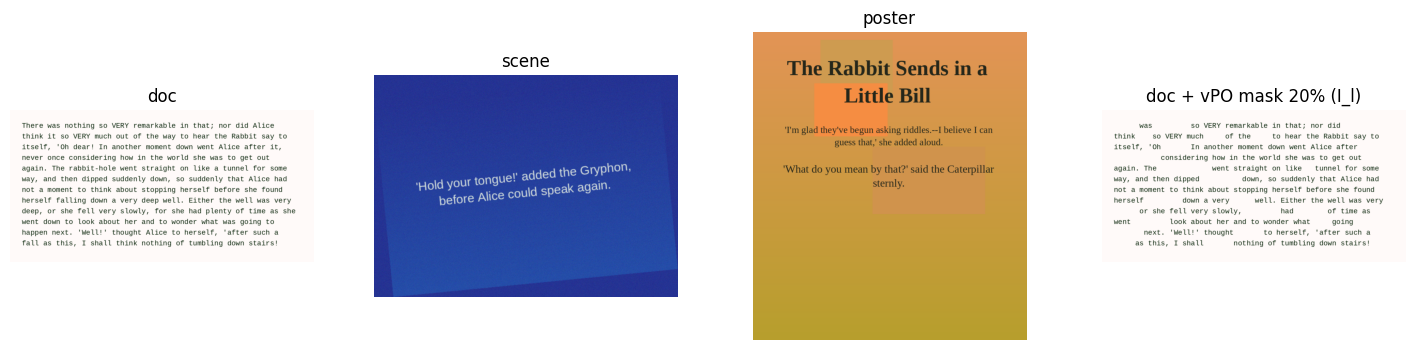

In [5]:
sent, short_heads = DATA["sent"], DATA["short"]
rng = random.Random(CFG.seed)
chunks = [sent[i:i+5] for i in range(0,len(sent),5)]
ids = list(range(len(chunks))); rng.shuffle(ids); n_test = max(3, round(0.2*len(chunks))); test_ids = set(ids[:n_test])
train_chunks = [c for i,c in enumerate(chunks) if i not in test_ids]; test_chunks = [c for i,c in enumerate(chunks) if i in test_ids]
train_sents = [p for c in train_chunks for p in c];                   test_sents = [p for c in test_chunks for p in c]
sh = short_heads[:]; rng.shuffle(sh); n_sh = max(5, round(0.2*len(sh))); test_heads, train_heads = sh[:n_sh], sh[n_sh:]
print(f"{len(sent)} cặp câu ({len(train_sents)} train / {len(test_sents)} test) | {len(short_heads)} tiêu đề ({len(train_heads)} train / {len(test_heads)} test)")

_sid = itertools.count(1)
def S(task,kind,pairs): return Sample(task,kind,[p[0] for p in pairs],[p[1] for p in pairs],next(_sid))
def mk(task,kind,chs,sents,heads,rng):
    if kind=="doc":
        c=rng.choice([c for c in chs if len(c)>=3]); k=rng.randint(3,min(5,len(c))); st=rng.randint(0,len(c)-k); return S(task,kind,c[st:st+k])
    if kind=="scene":
        pool=[p for p in sents if len(p[0])<=130] or sents; return S(task,kind,[rng.choice(pool)])
    pool=[p for p in sents if len(p[0])<=110] or sents
    return S(task,kind,[rng.choice(heads)]+[rng.choice(pool) for _ in range(rng.randint(1,2))])
def make_set(task,n,kinds,w,seed):
    r=random.Random(seed); return [mk(task,r.choices(kinds,w)[0],train_chunks,train_sents,train_heads,r) for _ in range(n)]

KINDS,W3 = ("doc","scene","poster"),(0.4,0.3,0.3)
PRE = make_set("ocr_en",CFG.n_ocr,KINDS,W3,11) + make_set("mt",CFG.n_mt,("doc","scene"),(0.6,0.4),12)
FT  = make_set("timt",CFG.n_ft,KINDS,W3,21)

re_ = random.Random(CFG.seed+7); pool_t = [p for p in test_sents if len(p[0])<=110] or test_sents
doc_e=[]
for c in test_chunks:
    if len(c)>=3:
        doc_e.append(S("timt","doc",c))
        if len(c)>3: doc_e.append(S("timt","doc",c[:3]))
doc_e=doc_e[:CFG.n_eval_doc]
scene_e=[S("timt","scene",[p]) for p in re_.sample(test_sents,min(CFG.n_eval_scene,len(test_sents)))]
poster_e=[S("timt","poster",[h]+[re_.choice(pool_t) for _ in range(re_.randint(1,2))]) for h in test_heads for _ in range(2)]
EVAL={"doc":doc_e,"scene":scene_e,"poster":poster_e}
print("PRE:",len(PRE),"| FT:",len(FT),"| EVAL:",{k:len(v) for k,v in EVAL.items()})

INSTR_TIMT = "Translate the text in image into Chinese"
INSTR_OCR  = "Please output the OCR result of the text in this image."
def instr_and_answer(s):
    if s.task=="timt":   return INSTR_TIMT, s.vi_text()
    if s.task=="ocr_en": return INSTR_OCR,  s.en_text()
    return "Translate the following English text into Chinese:\n"+s.en_text(), s.vi_text()

fig,ax=plt.subplots(1,4,figsize=(18,4)); d=[EVAL["doc"][0],EVAL["scene"][0],EVAL["poster"][0]]
for a,s in zip(ax,d): a.imshow(render_sample(s)); a.set_title(s.kind); a.axis("off")
ax[3].imshow(render_sample(d[0],CFG.mask_ratio)); ax[3].set_title("doc + vPO mask 20% (I_l)"); ax[3].axis("off"); plt.show()

In [6]:
OUT = "timt_mc"
os.makedirs(f"{OUT}/img", exist_ok=True)
to_pil = lambda x: x if isinstance(x, Image.Image) else Image.fromarray(np.asarray(x).astype("uint8"), "RGB")

def make_rejected(zh, rng, min_total=80, factor=1.5):
    """rPO (Mục 4.2): chọn 1 đoạn ngẫu nhiên của nhãn, cắt phần SAU đoạn đó, lặp đoạn đến độ dài tối đa.
    Giả định của giáo viên: đoạn dài 2–8 ký tự; độ dài tối đa = max(80, 1.5 × độ dài nhãn)."""
    seg_len = min(rng.randint(2, 8), len(zh)); start = rng.randint(0, len(zh) - seg_len)
    seg, prefix = zh[start:start + seg_len], zh[:start]
    total = max(min_total, int(len(zh) * factor)); reps = math.ceil((total - len(prefix)) / len(seg))
    return (prefix + seg * reps)[:total]

def export_all():
    rng = random.Random(CFG.seed + 99)
    pre, sft, rpo, vpo, ev = [], [], [], [], []
    for i, s in enumerate(PRE):
        q, a = instr_and_answer(s); name = f"pre{i:04d}"
        if s.task == "ocr_en":
            to_pil(render_sample(s)).save(f"{OUT}/img/{name}.png")
            pre.append(dict(id=name, image=f"img/{name}.png", query=q, answer=a, task="ocr_en", cls=s.kind))
        else:
            pre.append(dict(id=name, image=None, query=q, answer=a, task="mt", cls=s.kind))
    for i, s in enumerate(FT):
        q, a = instr_and_answer(s); name = f"ft{i:04d}"
        to_pil(render_sample(s)).save(f"{OUT}/img/{name}_w.png")
        sft.append(dict(id=name, image=f"img/{name}_w.png", query=q, answer=a, task="timt", cls=s.kind))
        if i < CFG.n_dpo:
            to_pil(render_sample(s, CFG.mask_ratio)).save(f"{OUT}/img/{name}_l.png")
            rpo.append(dict(id=name, image=f"img/{name}_w.png", query=q, chosen=a, rejected=make_rejected(a, rng), cls=s.kind))
            vpo.append(dict(id=name, image_chosen=f"img/{name}_w.png", image_rejected=f"img/{name}_l.png", query=q, answer=a, cls=s.kind))
    for cls, S_ in EVAL.items():
        for j, s in enumerate(S_):
            name = f"ev_{cls}_{j:03d}"; to_pil(render_sample(s)).save(f"{OUT}/img/{name}.png")
            ev.append(dict(id=name, image=f"img/{name}.png", query=INSTR_TIMT, reference=s.vi_text(), en=s.en_text(), cls=cls,
                           reference_type="pseudo (dịch máy)"))
    for fn, rows in (("pre", pre), ("sft", sft), ("rpo", rpo), ("vpo", vpo), ("eval", ev)):
        with open(f"{OUT}/{fn}.jsonl", "w", encoding="utf-8") as f:
            for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"pre={len(pre)} (OCR {sum(r['task']=='ocr_en' for r in pre)}, MT {sum(r['task']=='mt' for r in pre)}) | "
          f"sft={len(sft)} | rpo={len(rpo)} | vpo={len(vpo)} | eval={len(ev)} {({k: len(v) for k, v in EVAL.items()})} -> ./{OUT}")
export_all()


/tmp/ipykernel_539/1033202358.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img=Image.fromarray(arr.astype("uint8"),"RGB")


pre=48 (OCR 24, MT 24) | sft=48 | rpo=24 | vpo=24 | eval=52 {'doc': 24, 'scene': 18, 'poster': 10} -> ./timt_mc


In [7]:
%%writefile mcdpo_loss.py
"""
mcDPO loss cho InImageTrans (Zuo et al., ACL Findings 2025), Muc 4.2, Cong thuc (5), (6), (7).

Moi ham nhan LOG-XAC-SUAT CUA CA CHUOI DAP AN (tong log-prob cac token dap an), tinh boi:
  - policy : mo hinh dang huan luyen (pi_theta)
  - ref    : ban sao dong bang (pi_ref). Bai ghi "reference model"; viec ref la
             ban sao cua mo hinh sau SFT la CACH HIEU CUA GIAO VIEN, can kiem tra lai trong repo cua bai.

Ky hieu (dung theo bai):
  I_w: anh goc | I_l: anh bi che ~20% chu | y_w: nhan dung | y_l: nhan lap (rejected)
  beta = 0.1 (bai, Muc A.3)

TRANG THAI: cong thuc da duoc doi chieu voi bai. Ban torch nay CHUA chay thu o sandbox cua giao vien
(sandbox khong co torch). Hay chay phan self-test o cuoi file tren Colab truoc khi dung.
"""
import torch
import torch.nn.functional as F


def sequence_logprob(logits, input_ids, answer_mask):
    """Tong log-prob cac token DAP AN.
    logits: [B, T, V] | input_ids: [B, T] | answer_mask: [B, T], 1 tai vi tri token dap an.
    """
    logits = logits[:, :-1, :].float()
    labels = input_ids[:, 1:]
    mask = answer_mask[:, 1:].float()
    logp = torch.log_softmax(logits, dim=-1).gather(-1, labels.unsqueeze(-1)).squeeze(-1)
    return (logp * mask).sum(dim=-1)


def _dpo_term(pol_good, ref_good, pol_bad, ref_bad, beta):
    margin = (pol_good - ref_good) - (pol_bad - ref_bad)
    return -F.logsigmoid(beta * margin).mean()


def rpo_loss(pol_yw_Iw, ref_yw_Iw, pol_yl_Iw, ref_yl_Iw, beta=0.1):
    """Cong thuc (5): cung anh I_w, so sanh nhan dung y_w voi nhan lap y_l."""
    return _dpo_term(pol_yw_Iw, ref_yw_Iw, pol_yl_Iw, ref_yl_Iw, beta)


def vpo_loss(pol_yw_Iw, ref_yw_Iw, pol_yw_Il, ref_yw_Il, beta=0.1):
    """Cong thuc (6): cung nhan y_w, so sanh anh goc I_w voi anh bi che I_l."""
    return _dpo_term(pol_yw_Iw, ref_yw_Iw, pol_yw_Il, ref_yw_Il, beta)


def mcdpo_loss(pol_yw_Iw, ref_yw_Iw, pol_yl_Iw, ref_yl_Iw,
               pol_yw_Il, ref_yw_Il, beta=0.1):
    """Cong thuc (7): l_mcDPO = l_rPO + l_vPO.
    Moi mau can 3 luot forward cho policy va 3 cho ref:
      (I_w, y_w), (I_w, y_l), (I_l, y_w).
    """
    l_r = rpo_loss(pol_yw_Iw, ref_yw_Iw, pol_yl_Iw, ref_yl_Iw, beta)
    l_v = vpo_loss(pol_yw_Iw, ref_yw_Iw, pol_yw_Il, ref_yw_Il, beta)
    return l_r + l_v, l_r.detach(), l_v.detach()


if __name__ == "__main__":
    torch.manual_seed(0)
    a = torch.randn(8) - 20.0
    b = torch.randn(8) - 30.0
    l, lr, lv = mcdpo_loss(a, a, b, b, a, a)
    print("policy==ref:", float(lr), float(lv), "(ky vong ~0.6931 moi so hang)")
    assert abs(float(lr) - 0.6931) < 1e-3 and abs(float(lv) - 0.6931) < 1e-3
    l2, _, _ = mcdpo_loss(a + 5, a, b, b, a + 5, a)
    print("sau khi tang p(y_w):", float(l2), "<", float(l))
    assert float(l2) < float(l)
    logits = torch.randn(2, 6, 10)
    ids = torch.randint(0, 10, (2, 6))
    mask = torch.tensor([[0, 0, 1, 1, 1, 1], [0, 0, 0, 1, 1, 1]])
    print("sequence_logprob:", sequence_logprob(logits, ids, mask).shape, "(ky vong torch.Size([2]))")
    print("OK")


Writing mcdpo_loss.py


In [8]:
!python mcdpo_loss.py

policy==ref: 0.6931471824645996 0.6931471824645996 (ky vong ~0.6931 moi so hang)
sau khi tang p(y_w): 1.1672241687774658 < 1.3862943649291992
sequence_logprob: torch.Size([2]) (ky vong torch.Size([2]))
OK


In [9]:
%%writefile timt_metrics.py
"""
Do luong ao giac LAP / BO SOT va chat luong dich (bam theo Muc 6.1, A.5 cua bai InImageTrans).

TRUNG THUC ve nhung gi la cua bai va nhung gi la cua giao vien:
- Repetition_4 (cong thuc 8): 1 - |unique(4-gram)| / |4-gram|, tinh tren KY TU. Bai viet
  "unique(4_grams) = bon ky tu lien tiep chua bi lap"; o day hieu la SO 4-gram KHAC NHAU (cach
  hieu cua giao vien, can doi chieu voi Xu et al. 2022).
- Co lap (repetition candidate): bai dung "do dai dau ra vuot xa tham chieu va co 10 lan lap lien tiep",
  sau do nguoi doc xac nhan. O day: regex bat chuoi 1-20 ky tu lap >= 10 lan lien tiep (cach cai dat cua
  giao vien). Khong co buoc nguoi xac nhan.
- Co bo sot (omission candidate): bai dung "do dai dau ra NGAN HON NHIEU so voi tham chieu". Nguong
  "nhieu" bai khong neu; o day dung ti le do dai < 0.5 (GIA DINH cua giao vien). Day chi la ung vien,
  khong phai ket luan bo sot.
- BLEU: bai dung sacreBLEU; cach tach tu tieng Trung bai khong neu. O day dung tokenize="zh" (can kiem tra).
"""
import re

_REP_RE = re.compile(r"(.{1,20}?)\1{9,}", re.S)


def has_repetition(text):
    return _REP_RE.search(text) is not None


def repetition_4(text):
    text = re.sub(r"\s+", "", text)
    grams = [text[i:i + 4] for i in range(len(text) - 3)]
    if not grams:
        return 0.0
    return 1.0 - len(set(grams)) / len(grams)


def length_ratio(hyp, ref):
    return len(re.sub(r"\s+", "", hyp)) / max(1, len(re.sub(r"\s+", "", ref)))


def evaluate(hyps, refs, over=2.0, under=0.5):
    assert len(hyps) == len(refs) and len(hyps) > 0
    n = len(hyps)
    ratios = [length_ratio(h, r) for h, r in zip(hyps, refs)]
    rep_flags = [has_repetition(h) and ra > over for h, ra in zip(hyps, ratios)]
    rep_any = [has_repetition(h) for h in hyps]
    omit = [ra < under for ra in ratios]
    out = {
        "n": n,
        "repetition_rate": sum(rep_flags) / n,
        "repetition_rate_loose": sum(rep_any) / n,
        "omission_candidate_rate": sum(omit) / n,
        "repetition_4": sum(repetition_4(h) for h in hyps) / n,
        "len_ratio_mean": sum(ratios) / n,
        "bleu": None,
    }
    try:
        import sacrebleu
        out["bleu"] = sacrebleu.corpus_bleu(hyps, [refs], tokenize="zh").score
    except ImportError:
        pass
    return out


if __name__ == "__main__":
    ref = "本校园内禁止吸烟，请勿在建筑物内使用任何烟草制品。"
    good = ref
    rep = "本校园内禁止" + "吸烟。" * 40
    short = "本校园"
    r = evaluate([good, rep, short], [ref, ref, ref])
    print(r)
    assert has_repetition(rep) and not has_repetition(good)
    assert repetition_4(rep) > 0.8 and repetition_4(good) < 0.2
    assert abs(r["repetition_rate"] - 1 / 3) < 1e-9 and abs(r["omission_candidate_rate"] - 1 / 3) < 1e-9
    print("OK")


Writing timt_metrics.py


In [10]:
!python timt_metrics.py

{'n': 3, 'repetition_rate': 0.3333333333333333, 'repetition_rate_loose': 0.3333333333333333, 'omission_candidate_rate': 0.3333333333333333, 'repetition_4': 0.3089430894308943, 'len_ratio_mean': 2.0533333333333332, 'bleu': 21.240453860656714}
OK


In [11]:
%%writefile timt_train.py
"""
SFT -> mcDPO -> danh gia (co/khong RPD) cho TiMT Anh->Trung, quy mo nho, tren Colab ~16GB.

!!! TRANG THAI: BAN NHAP, CHUA TUNG CHAY. Sandbox cua giao vien khong co GPU/torch/transformers nen chi
kiem tra duoc cu phap. Hay chay "smoke test" truoc (--max-steps 2, --n 2) va dan loi lai neu co. !!!

GIAI THICH LUA CHON (khac bai, can ghi vao bao cao):
- Bai xay mo hinh InImageTrans 8,12B tham so (CLIP-ViT-L/14 + bo ma hoa Vary + Qwen-chat 7B),
  pre-train 1,2 trieu mau tren 8xA100. Khong lam duoc tren Colab 16GB.
- Thay vao do: dung MLLM da pre-train san, nho (Qwen2-VL-2B-Instruct) + LoRA, roi ap dung dung hai
  thanh phan cot loi cua bai: SFT (cong thuc 4) va mcDPO (cong thuc 5-7), cung giai ma tham lam + RPD.
  Bai cung tu ap dung SFT + mcDPO len Qwen2-VL-8B va InternVL2-8B (Bang 15), nen huong nay co can cu.
- KHONG tai hien: kien truc hai bo ma hoa, pre-train OCR/MT, benchmark MCiT that.
- Cac tham so DUOI DAY la cua giao vien (bai khong neu): lr, LoRA r, so epoch, max_pixels, repetition_penalty.
  Bai chi neu: beta=0.1, batch 8 (mcDPO), 1 epoch (mcDPO), giai ma tham lam + RPD (Keskar 2019).
- mo hinh tham chieu pi_ref = mo hinh sau SFT (adapter SFT duoc gop vao, adapter mcDPO moi duoc tat). Day
  la cach hieu cua giao vien, can doi chieu voi repo cua bai.
"""
import argparse
import json
import os
import random
import time

import torch
from PIL import Image

from mcdpo_loss import rpo_loss, vpo_loss, mcdpo_loss
from timt_metrics import evaluate

MODEL = "Qwen/Qwen2-VL-2B-Instruct"
T0 = time.time()


def stats():
    """Bo nho GPU dinh (GiB) va thoi gian da troi qua (giay) - de TU DO, khong phai uoc luong."""
    peak = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0
    return f"peak_mem={peak:.1f}GiB t={time.time() - T0:.0f}s"


def read_jsonl(path):
    return [json.loads(l) for l in open(path, encoding="utf-8")]


def load_processor(max_pixels):
    from transformers import AutoProcessor
    return AutoProcessor.from_pretrained(MODEL, min_pixels=64 * 28 * 28, max_pixels=max_pixels)


def load_model(adapters=()):
    """Nap mo hinh goc fp16; moi adapter trong `adapters` duoc nap roi GOP vao trong so."""
    from transformers import Qwen2VLForConditionalGeneration
    from peft import PeftModel
    model = Qwen2VLForConditionalGeneration.from_pretrained(MODEL, torch_dtype=torch.float16).cuda()
    for path in adapters:
        model = PeftModel.from_pretrained(model, path).merge_and_unload()
    model.config.use_cache = False
    return model


def add_lora(model, r):
    from peft import LoraConfig, get_peft_model
    model.gradient_checkpointing_enable()
    model.enable_input_require_grads()
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.0, task_type="CAUSAL_LM",
                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, cfg)
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    model.print_trainable_parameters()
    return model


def prompt_text(processor, query, with_image=True):
    content = ([{"type": "image"}] if with_image else []) + [{"type": "text", "text": query}]
    msgs = [{"role": "user", "content": content}]
    return processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


def build(processor, root, image, query, answer):
    """Tra ve (enc, prompt_len). Token dap an la cac vi tri >= prompt_len."""
    prompt = prompt_text(processor, query, with_image=image is not None)
    if image is None:
        plen = processor(text=[prompt], return_tensors="pt")["input_ids"].shape[1]
        enc = processor(text=[prompt + answer + "<|im_end|>"], return_tensors="pt")
    else:
        img = Image.open(os.path.join(root, image)).convert("RGB")
        plen = processor(text=[prompt], images=[img], return_tensors="pt")["input_ids"].shape[1]
        enc = processor(text=[prompt + answer + "<|im_end|>"], images=[img], return_tensors="pt")
    return {k: v.cuda() for k, v in enc.items()}, plen


def answer_logp(model, enc, plen, grad):
    """Tong log-prob cac token dap an (va so token). Chi tinh softmax tren doan dap an de tiet kiem bo nho."""
    with torch.set_grad_enabled(grad), torch.autocast("cuda", dtype=torch.float16):
        logits = model(**enc).logits
    ids = enc["input_ids"]
    lg = logits[:, plen - 1:-1, :].float()
    labels = ids[:, plen:]
    logp = torch.log_softmax(lg, dim=-1).gather(-1, labels.unsqueeze(-1)).squeeze(-1)
    return logp.sum(), labels.shape[1]


def run_sft(a):
    processor = load_processor(a.max_pixels)
    if a.init:
        from peft import PeftModel
        model = load_model()
        model.gradient_checkpointing_enable(); model.enable_input_require_grads()
        model = PeftModel.from_pretrained(model, a.init, is_trainable=True)
        for p in model.parameters():
            if p.requires_grad:
                p.data = p.data.float()
    else:
        model = add_lora(load_model(), a.lora_r)
    rows = read_jsonl(os.path.join(a.data, a.file))[: a.n]
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=a.lr, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda")
    model.train()
    step = 0
    for ep in range(a.epochs):
        random.Random(ep).shuffle(rows)
        for i, r in enumerate(rows):
            enc, plen = build(processor, a.data, r["image"], r["query"], r["answer"])
            logp, n = answer_logp(model, enc, plen, grad=True)
            loss = -logp / n / a.accum
            scaler.scale(loss).backward()
            if (i + 1) % a.accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
                if step % 10 == 0 or step <= 2:
                    print(f"[sft] ep{ep} step{step} nll/token={-(logp / n).item():.4f} | {stats()}", flush=True)
                if a.max_steps and step >= a.max_steps:
                    break
        if a.max_steps and step >= a.max_steps:
            break
    model.save_pretrained(a.out)
    print("Da luu adapter SFT ->", a.out, "|", stats())



def run_mcdpo(a):
    processor = load_processor(a.max_pixels)
    model = add_lora(load_model(adapters=[a.sft]), a.lora_r)
    rpo = {r["id"]: r for r in read_jsonl(os.path.join(a.data, "rpo.jsonl"))}
    vpo = {r["id"]: r for r in read_jsonl(os.path.join(a.data, "vpo.jsonl"))}
    ids = sorted(rpo.keys() & vpo.keys())[: a.n]
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=a.lr, weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda")
    model.train()
    step = 0
    for ep in range(a.epochs):
        random.Random(ep).shuffle(ids)
        for i, k in enumerate(ids):
            r, v = rpo[k], vpo[k]
            q = r["query"]

            e_ww, p_ww = build(processor, a.data, r["image"], q, r["chosen"])
            e_wl, p_wl = build(processor, a.data, r["image"], q, r["rejected"])
            e_lw, p_lw = build(processor, a.data, v["image_rejected"], q, v["answer"])
            with model.disable_adapter():
                with torch.no_grad():
                    ref_ww = answer_logp(model, e_ww, p_ww, grad=False)[0]
                    ref_wl = answer_logp(model, e_wl, p_wl, grad=False)[0] if a.mode != "vpo" else ref_ww
                    ref_lw = answer_logp(model, e_lw, p_lw, grad=False)[0] if a.mode != "rpo" else ref_ww
            pol_ww = answer_logp(model, e_ww, p_ww, grad=True)[0]
            pol_wl = answer_logp(model, e_wl, p_wl, grad=True)[0] if a.mode != "vpo" else pol_ww
            pol_lw = answer_logp(model, e_lw, p_lw, grad=True)[0] if a.mode != "rpo" else pol_ww
            f = lambda t: t.reshape(1)
            if a.mode == "mcdpo":
                loss, l_r, l_v = mcdpo_loss(f(pol_ww), f(ref_ww), f(pol_wl), f(ref_wl), f(pol_lw), f(ref_lw), a.beta)
            elif a.mode == "rpo":
                loss = rpo_loss(f(pol_ww), f(ref_ww), f(pol_wl), f(ref_wl), a.beta)
            else:
                loss = vpo_loss(f(pol_ww), f(ref_ww), f(pol_lw), f(ref_lw), a.beta)
            scaler.scale(loss / a.accum).backward()
            if (i + 1) % a.accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
                if step % 5 == 0 or step <= 2:
                    print(f"[mcdpo:{a.mode}] ep{ep} step{step} loss={loss.item():.4f} | {stats()}", flush=True)
                if a.max_steps and step >= a.max_steps:
                    break
        if a.max_steps and step >= a.max_steps:
            break
    model.save_pretrained(a.out)
    print("Da luu adapter mcDPO ->", a.out, "|", stats())


def generate_zh(model, processor, img, query, rp, max_new):
    enc = processor(text=[prompt_text(processor, query)], images=[img], return_tensors="pt")
    enc = {k: v.cuda() for k, v in enc.items()}
    out = model.generate(**enc, max_new_tokens=max_new, do_sample=False,
                         repetition_penalty=rp, use_cache=True)
    return processor.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)[0]


@torch.no_grad()
def run_eval(a):
    processor = load_processor(a.max_pixels)
    model = load_model(adapters=a.adapters)
    model.config.use_cache = True
    model.eval()
    rows = read_jsonl(os.path.join(a.data, "eval.jsonl"))[: a.n]
    hyps = []
    for r in rows:
        img = Image.open(os.path.join(a.data, r["image"])).convert("RGB")
        hyps.append(generate_zh(model, processor, img, r["query"], a.rp, a.max_new))
    os.makedirs("results", exist_ok=True)
    refs = [r["reference"] for r in rows]
    res = evaluate(hyps, refs)
    res["per_class"] = {}
    for c in sorted({r.get("cls", "all") for r in rows}):
        idx = [i for i, r in enumerate(rows) if r.get("cls", "all") == c]
        res["per_class"][c] = evaluate([hyps[i] for i in idx], [refs[i] for i in idx])
    res.update({"tag": a.tag, "adapters": list(a.adapters), "repetition_penalty": a.rp})
    json.dump(res, open(f"results/{a.tag}.json", "w"), ensure_ascii=False, indent=1)
    with open(f"results/{a.tag}_outputs.jsonl", "w", encoding="utf-8") as f:
        for r, h in zip(rows, hyps):
            f.write(json.dumps({"id": r["id"], "cls": r.get("cls"), "hyp": h, "ref": r["reference"]}, ensure_ascii=False) + "\n")
    print(f"[{a.tag}] BLEU tổng {res['bleu']}", {c: (round(v['bleu'], 2) if v['bleu'] is not None else None) for c, v in res["per_class"].items()})
    print(f"[eval] {len(rows)} mẫu | {stats()}")


@torch.no_grad()
def run_translate(a):
    processor = load_processor(a.max_pixels)
    model = load_model(adapters=a.adapters)
    model.config.use_cache = True
    model.eval()
    for p in a.images:
        img = Image.open(p).convert("RGB")
        print("=" * 60, "\n", p, "\n", generate_zh(model, processor, img, a.query, a.rp, a.max_new))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("stage", choices=["sft", "mcdpo", "eval", "translate"])
    ap.add_argument("--data", default="timt_mc")
    ap.add_argument("--out", default="ckpt")
    ap.add_argument("--file", default="sft.jsonl", help="sft: tệp dữ liệu (pre.jsonl hoặc sft.jsonl)")
    ap.add_argument("--init", default="", help="sft: adapter để huấn luyện tiếp (pre-train -> fine-tune)")
    ap.add_argument("--images", nargs="*", default=[], help="translate: danh sách ảnh cần dịch")
    ap.add_argument("--query", default="Translate the text in image into Chinese")
    ap.add_argument("--sft", default="ckpt_sft", help="adapter SFT (dung cho mcdpo)")
    ap.add_argument("--adapters", nargs="*", default=[], help="eval: danh sach adapter nap va gop theo thu tu")
    ap.add_argument("--tag", default="run")
    ap.add_argument("--mode", default="mcdpo", choices=["mcdpo", "rpo", "vpo"])
    ap.add_argument("--n", type=int, default=10**9, help="gioi han so mau (dung de smoke test)")
    ap.add_argument("--epochs", type=int, default=1)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--beta", type=float, default=0.1)
    ap.add_argument("--accum", type=int, default=8)
    ap.add_argument("--lora-r", type=int, default=16)
    ap.add_argument("--max-pixels", type=int, default=768 * 28 * 28)
    ap.add_argument("--max-new", type=int, default=512)
    ap.add_argument("--rp", type=float, default=1.0, help="repetition_penalty; 1.0 = khong RPD")
    ap.add_argument("--max-steps", type=int, default=0)
    a = ap.parse_args()
    {"sft": run_sft, "mcdpo": run_mcdpo, "eval": run_eval, "translate": run_translate}[a.stage](a)


if __name__ == "__main__":
    main()


Writing timt_train.py


In [12]:
!python timt_train.py eval --tag A_base_noRPD
!python timt_train.py eval --tag B_base_RPD --rp 1.1

preprocessor_config.json: 100% 347/347 [00:00<00:00, 549kB/s]
chat_template.json: 100% 1.05k/1.05k [00:00<00:00, 260kB/s]
config.json: 100% 1.20k/1.20k [00:00<00:00, 3.17MB/s]
tokenizer_config.json: 100% 4.19k/4.19k [00:00<00:00, 9.73MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 44.1MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 39.1MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 57.4MB/s]
model.safetensors.index.json: 100% 56.4k/56.4k [00:00<00:00, 123MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/4.42G [00:00<?, ?B/s]         

Reconstructing (incomplete total...):  90% 3.97G/4.42G [00:41<00:07, 62.8MB/s, 69.2MB/s  ]
Reconstructing (incomplete total...): 100% 4.42G/4.42G [00:55<00:00, 47.2MB/s, 62.8MB/s  ]

Fetching 2 files: 100% 2/2 [00:55<00:00, 27.89s/it]
Download complete: 100% 3.83G/3.83G [00:55<00:00, 114MB/s,  114MB/s  ]
Download complete

In [13]:
!python timt_train.py sft --file pre.jsonl --out ckpt_pre --epochs 1 --lr 1e-4 --accum 8

Loading weights: 100% 729/729 [00:18<00:00, 40.27it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[sft] ep0 step1 nll/token=0.4183 | peak_mem=4.9GiB t=55s
[sft] ep0 step2 nll/token=0.4808 | peak_mem=5.0GiB t=73s
Da luu adapter SFT -> ckpt_pre | peak_mem=5.0GiB t=147s


In [14]:
!python timt_train.py sft --file sft.jsonl --init ckpt_pre --out ckpt_ft --epochs 2 --lr 1e-4 --accum 8
!python timt_train.py eval --adapters ckpt_ft --tag C_ft_noRPD
!python timt_train.py eval --adapters ckpt_ft --rp 1.1 --tag D_ft_RPD

Loading weights: 100% 729/729 [00:18<00:00, 40.21it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[sft] ep0 step1 nll/token=2.2214 | peak_mem=4.9GiB t=52s
[sft] ep0 step2 nll/token=2.4471 | peak_mem=5.0GiB t=73s
[sft] ep1 step10 nll/token=1.7540 | peak_mem=5.1GiB t=216s
Da luu adapter SFT -> ckpt_ft | peak_mem=5.1GiB t=251s
Loading weights: 100% 729/729 [00:15<00:00, 46.96it/s]
/usr

In [15]:
!python timt_train.py mcdpo --sft ckpt_ft --mode mcdpo --lr 2e-5 --out ckpt_mcdpo --accum 8
!python timt_train.py eval --adapters ckpt_ft ckpt_mcdpo --tag E_mcdpo_noRPD
!python timt_train.py eval --adapters ckpt_ft ckpt_mcdpo --rp 1.1 --tag F_mcdpo_RPD

Loading weights: 100% 729/729 [00:15<00:00, 46.94it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[mcdpo:mcdpo] ep0 step1 loss=1.3863 | peak_mem=5.7GiB t=87s
[mcdpo:mcdpo] ep0 step2 loss=1.3690 | peak_mem=5.8GiB t=151s
Da luu adapter mcDPO -> ckpt_mcdpo | peak_mem=5.8GiB t=220s
Loading weights: 100% 729/

In [16]:
!python timt_train.py mcdpo --sft ckpt_ft --mode rpo --lr 2e-5 --out ckpt_rpo_only --accum 8
!python timt_train.py eval --adapters ckpt_ft ckpt_rpo_only --rp 1.1 --tag G_wo_vPO
!python timt_train.py mcdpo --sft ckpt_ft --mode vpo --lr 2e-5 --out ckpt_vpo_only --accum 8
!python timt_train.py eval --adapters ckpt_ft ckpt_vpo_only --rp 1.1 --tag H_wo_rPO

Loading weights: 100% 729/729 [00:16<00:00, 44.49it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[mcdpo:rpo] ep0 step1 loss=0.6931 | peak_mem=5.3GiB t=69s
[mcdpo:rpo] ep0 step2 loss=0.6784 | peak_mem=5.4GiB t=111s
Da luu adapter mcDPO -> ckpt_rpo_only | peak_mem=5.4GiB t=159s
Loading weights: 100% 729/7

In [17]:
import glob
rows = []
for f in sorted(glob.glob("results/*.json")):
    r = json.load(open(f, encoding="utf-8")); pc = r.get("per_class", {})
    rows.append(dict(tag=r["tag"], rp=r["repetition_penalty"], BLEU=r["bleu"],
                     **{f"BLEU_{c}": pc[c]["bleu"] for c in ("doc", "scene", "poster") if c in pc},
                     lap_pct=100 * r["repetition_rate"], bo_sot_pct=100 * r["omission_candidate_rate"],
                     Rep4_pct=100 * r["repetition_4"], n=r["n"]))
df = pd.DataFrame(rows); display(df.round(2))
def gate(b): return "ĐẠT 15" if b is not None and b >= 15 else ("ĐẠT 10" if b is not None and b >= 10 else "CHƯA ĐẠT")
for _, r in df.iterrows():
    print(f"{r['tag']:22s} BLEU tổng {r['BLEU']:.2f} -> {gate(r['BLEU'])} | " + " | ".join(f"{c}: {r[f'BLEU_{c}']:.1f} ({gate(r[f'BLEU_{c}'])})" for c in ("doc", "scene", "poster") if f"BLEU_{c}" in r))
for tag in ("A_base_noRPD", "D_ft_RPD", "F_mcdpo_RPD"):
    p = f"results/{tag}_outputs.jsonl"
    if os.path.exists(p):
        for cls in ("doc", "scene", "poster"):
            o = [json.loads(l) for l in open(p, encoding="utf-8")]; o = [x for x in o if x["cls"] == cls][0]
            print(f"\n[{tag}] {cls}\n REF: {o['ref'][:160]}\n HYP: {o['hyp'][:160]}")

,tag,rp,BLEU,BLEU_doc,BLEU_scene,BLEU_poster,lap_pct,bo_sot_pct,Rep4_pct,n
0,A_base_noRPD,1.0,26.78,27.49,29.82,2.30,0.00,11.54,1.07,52
1,B_base_RPD,1.1,26.51,26.09,29.84,15.71,0.00,3.85,0.62,52
2,C_ft_noRPD,1.0,36.37,35.79,40.77,33.94,1.92,0.00,2.23,52
3,D_ft_RPD,1.1,38.22,38.44,39.79,31.69,0.00,0.00,0.81,52
4,E_mcdpo_noRPD,1.0,36.22,35.46,41.31,34.34,1.92,0.00,2.29,52
5,F_mcdpo_RPD,1.1,38.10,38.59,38.19,31.94,0.00,0.00,0.85,52
6,G_wo_vPO,1.1,38.22,38.56,39.26,31.94,0.00,0.00,0.82,52
7,H_wo_rPO,1.1,38.35,38.77,38.74,31.94,0.00,0.00,0.85,52


A_base_noRPD           BLEU tổng 26.78 -> ĐẠT 15 | doc: 27.5 (ĐẠT 15) | scene: 29.8 (ĐẠT 15) | poster: 2.3 (CHƯA ĐẠT)
B_base_RPD             BLEU tổng 26.51 -> ĐẠT 15 | doc: 26.1 (ĐẠT 15) | scene: 29.8 (ĐẠT 15) | poster: 15.7 (ĐẠT 15)
C_ft_noRPD             BLEU tổng 36.37 -> ĐẠT 15 | doc: 35.8 (ĐẠT 15) | scene: 40.8 (ĐẠT 15) | poster: 33.9 (ĐẠT 15)
D_ft_RPD               BLEU tổng 38.22 -> ĐẠT 15 | doc: 38.4 (ĐẠT 15) | scene: 39.8 (ĐẠT 15) | poster: 31.7 (ĐẠT 15)
E_mcdpo_noRPD          BLEU tổng 36.22 -> ĐẠT 15 | doc: 35.5 (ĐẠT 15) | scene: 41.3 (ĐẠT 15) | poster: 34.3 (ĐẠT 15)
F_mcdpo_RPD            BLEU tổng 38.10 -> ĐẠT 15 | doc: 38.6 (ĐẠT 15) | scene: 38.2 (ĐẠT 15) | poster: 31.9 (ĐẠT 15)
G_wo_vPO               BLEU tổng 38.22 -> ĐẠT 15 | doc: 38.6 (ĐẠT 15) | scene: 39.3 (ĐẠT 15) | poster: 31.9 (ĐẠT 15)
H_wo_rPO               BLEU tổng 38.35 -> ĐẠT 15 | doc: 38.8 (ĐẠT 15) | scene: 38.7 (ĐẠT 15) | poster: 31.9 (ĐẠT 15)

[A_base_noRPD] doc
 REF: 没有什么特别的, 爱丽丝认为它是如此之大听兔子对自己说,"哦,亲爱的!在另

In [1]:
import shlex
from google.colab import files
up = files.upload()
paths = [p for p in up.keys() if p.lower().endswith((".png", ".jpg", ".jpeg", ".webp", ".bmp"))]
if not paths:
    print("Chưa có ảnh hợp lệ. Chạy lại ô này và chọn một file ảnh (.png/.jpg).")
else:
    cmd = "python timt_train.py translate --adapters ckpt_ft ckpt_mcdpo --rp 1.1 --images " + " ".join(shlex.quote(p) for p in paths)
    !{cmd}

Saving Screenshot 2026-11-22 120256.png to Screenshot 2026-11-22 120256.png
Loading weights: 100% 729/729 [00:18<00:00, 38.58it/s]
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
 Screenshot 2026-11-22 120256.png 
 包括我的妹妹,是马里布加利福尼亚州的一家大戒毒中心的主任,她会把她的牌打出来,为重要的会议获取方向和灵感。她不会说她是塔罗牌占卜者,而是当她打电话时,她需要一个明确的主题和简短的信息,因为这是焦点。


In [20]:
import timt_train as T, gradio as gr
ADAPTERS = ["ckpt_ft", "ckpt_mcdpo"]
proc = T.load_processor(768 * 28 * 28); mdl = T.load_model(adapters=ADAPTERS); mdl.config.use_cache = True; mdl.eval()
def dich(img):
    if img is None: return ""
    with torch.no_grad(): return T.generate_zh(mdl, proc, img.convert("RGB"), "Translate the text in image into Chinese", 1.1, 512)
gr.Interface(fn=dich, inputs=gr.Image(type="pil", label="Ảnh có chữ tiếng Anh"),
             outputs=gr.Textbox(lines=8, label="Bản dịch tiếng Trung"),
             title="Dịch ảnh Anh → Trung (InImageTrans thu nhỏ trên Qwen2-VL)").launch(share=True)

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d0d8a2c814d63424a3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [21]:
from google.colab import drive; drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/timt_backup && cp -r ckpt_* results timt_mc/*.jsonl /content/drive/MyDrive/timt_backup/ 2>/dev/null; ls /content/drive/MyDrive/timt_backup

Mounted at /content/drive
ckpt_ft     ckpt_pre	   ckpt_vpo_only  pre.jsonl  rpo.jsonl	vpo.jsonl
ckpt_mcdpo  ckpt_rpo_only  eval.jsonl	  results    sft.jsonl


In [22]:
import shutil, glob
from google.colab import files
INCLUDE_CKPT = False
PACK = "timt_package"
shutil.rmtree(PACK, ignore_errors=True); os.makedirs(PACK + "/src"); os.makedirs(PACK + "/data")
for f in ("mcdpo_loss.py", "timt_metrics.py", "timt_train.py"): shutil.copy(f, PACK + "/src/")
shutil.copytree("timt_mc", PACK + "/data/timt_mc")
if os.path.exists("results"): shutil.copytree("results", PACK + "/results")
if os.path.exists(f"{CKPT_DIR}/book_en_zh.json"): shutil.copy(f"{CKPT_DIR}/book_en_zh.json", PACK + "/data/")
shutil.make_archive("timt_package", "zip", PACK)
print("kích thước:", round(os.path.getsize("timt_package.zip") / 2**20, 1), "MB")
files.download("timt_package.zip")

kích thước: 43.9 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>